In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("order.csv")

In [3]:
print(df.shape)
df.head()

(1000, 13)


,OrderID,CustomerID,OrderDate,OrderStatus,ShippedDate,ShipAddress,Unnamed: 6,Unnamed: 7,Unnamed: 8,ShipCountry,ShippingFee,PaymentMethod,TotalAmount
0,1,1,2/16/2012,pending,7/10/2021,30249 Donald Way,NaN,NaN,NaN,China,63.95,cash on delivery,1568.28
1,2,2,2/6/2012,processing,6/23/2014,97 David Street,NaN,NaN,NaN,Greece,75.62,cash on delivery,4654.31
2,3,3,1/2/2013,pending,10/22/2022,2024 Myrtle Parkway,NaN,NaN,NaN,Poland,453.17,PayPal,5810.01
3,4,4,2/28/2013,pending,11/22/2011,75158 Merry Plaza,NaN,NaN,NaN,Japan,883.25,PayPal,4388.28
4,5,5,8/28/2014,delivered,8/16/2017,875 Nancy Hill,NaN,NaN,NaN,Portugal,881.14,credit card,2972.23


Check the shape (rows, columns) and preview the first 5 rows.

In [4]:
df = df.dropna(axis=1, how='all')
print(df.shape)

(1000, 10)


Drop columns that are entirely empty

In [6]:
df.isnull().sum()

OrderID          0
CustomerID       0
OrderDate        0
OrderStatus      0
ShippedDate      0
ShipAddress      0
ShipCountry      0
ShippingFee      0
PaymentMethod    0
TotalAmount      0
dtype: int64

In [7]:
df.describe()

,OrderID,CustomerID,ShippingFee,TotalAmount
count,1000.000000,1000.000000,1000.000000,1000.000000
mean,500.500000,500.500000,505.834050,4850.371190
std,288.819436,288.819436,289.264579,2898.942152
min,1.000000,1.000000,0.410000,0.840000
25%,250.750000,250.750000,261.302500,2238.432500
50%,500.500000,500.500000,496.620000,4771.025000
75%,750.250000,750.250000,757.812500,7420.305000
max,1000.000000,1000.000000,999.930000,9979.460000


summary statistics

In [8]:
df[['TotalAmount', 'ShipCountry', 'PaymentMethod']].head()

,TotalAmount,ShipCountry,PaymentMethod
0,1568.28,China,cash on delivery
1,4654.31,Greece,cash on delivery
2,5810.01,Poland,PayPal
3,4388.28,Japan,PayPal
4,2972.23,Portugal,credit card


In [9]:
delivered = df[df['OrderStatus'] == 'delivered']
print(len(delivered))

228


Filter only the orders that have been delivered, and count them.

In [11]:
big_orders = df[df['TotalAmount'] > 5000]
print(big_orders)

     OrderID  CustomerID  OrderDate OrderStatus ShippedDate  \
2          3           3   1/2/2013     pending  10/22/2022   
5          6           6  5/25/2022   delivered   3/29/2012   
7          8           8  6/27/2021   delivered   8/28/2018   
8          9           9  2/18/2010  processing   9/25/2013   
11        12          12  5/21/2010     shipped    7/9/2017   
..       ...         ...        ...         ...         ...   
986      987         987   3/7/2019     shipped    5/8/2019   
987      988         988   5/3/2011  processing   11/1/2020   
988      989         989  1/16/2022   delivered    6/7/2019   
989      990         990  7/20/2014   delivered   12/9/2019   
991      992         992  5/22/2020     shipped   9/11/2018   

              ShipAddress ShipCountry  ShippingFee     PaymentMethod  \
2     2024 Myrtle Parkway      Poland       453.17            PayPal   
5     7556 Chinook Street       China        49.42            PayPal   
7       601 Bluejay Alley  

In [12]:
df.groupby('PaymentMethod')['TotalAmount'].mean()

PaymentMethod
PayPal              4898.159115
cash on delivery    4945.239129
credit card         4701.368170
Name: TotalAmount, dtype: float64

Group orders by payment method and compute the average order amount for each.

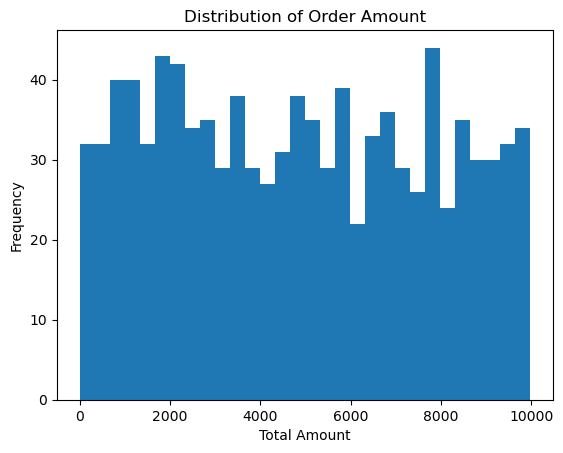

In [13]:
df['TotalAmount'].plot(kind='hist', bins=30)
plt.title('Distribution of Order Amount')
plt.xlabel('Total Amount')
plt.show()

Plot a histogram of order amounts

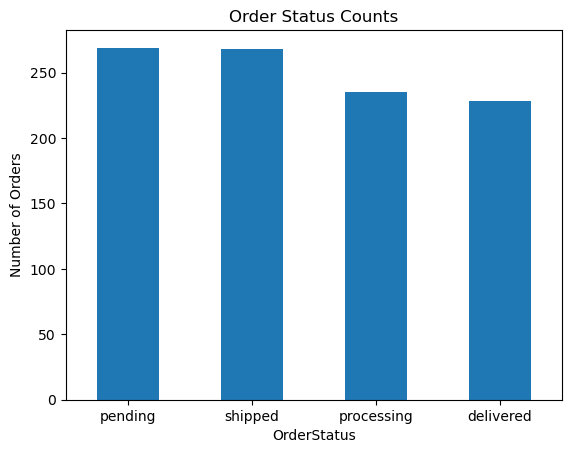

In [14]:
df['OrderStatus'].value_counts().plot(kind='bar')
plt.title('Order Status Counts')
plt.ylabel('Number of Orders')
plt.xticks(rotation=0)
plt.show()

Count orders in each status and plot as a bar chart.

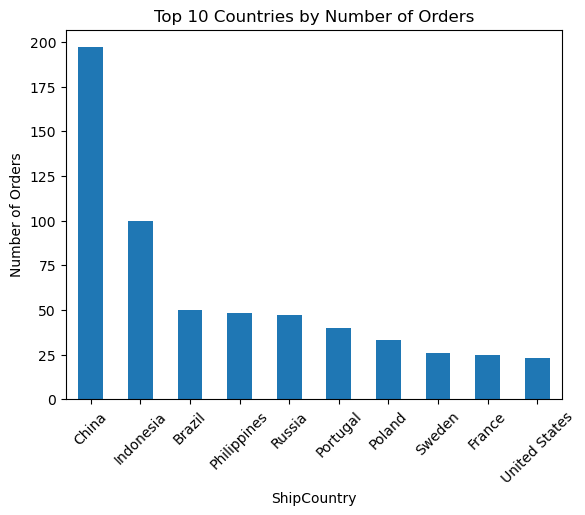

In [15]:
df['ShipCountry'].value_counts().head(10).plot(kind='bar')
plt.title('Top 10 Countries by Number of Orders')
plt.ylabel('Number of Orders')
plt.xticks(rotation=45)
plt.show()

Show the 10 countries with the most orders as a bar chart.


Five observations:
1. The data is clean: 1000 orders across 10 useful columns, with no missing values after dropping three empty columns.
2. Order amounts are roughly evenly distributed: mean 4850, median 4771, range 0.84 to 9979.
3. Order statuses are balanced across four states (pending, shipped, processing, delivered), each around 230-270 orders.
4. PayPal is the most popular payment method (373 orders), followed by credit card and cash on delivery.
5. China is the largest market with 197 orders, nearly double the second country (Indonesia, 100).